# 1.2 Information Gain

In this example, we show how to calculate the information gain from the ensemble of model samples generated in Example 1.1, and compare to the information gain under different experimental conditions.

In [1]:
#__ Import: Numerical __
import numpy as np

#__ Import: Topophone2 __
from topophone2.inversion import MarginalStats

#__ Import: Plotting __
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

Hello from topophone2!


In [2]:
#__ Set up: Plotting __
theme = ['#DC4424', '#74A466', '#24448C', '#F8BC5C']
small, large = 8, 10
plt.rcParams["font.sans-serif"] = ['Arial']

#__ Disable: Warnings __
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

### 1.2.1 Read inversion results

The inversion results in Example 1.1 were stored in the folder ``models/eg1/triad``. Equivalent results for an extra sensor added to the centre of the array were stored in the folder ``models/eg1/extra-receiver``, and for an increased noise level of 10dB in ``models/eg1/extra-noise``.

In [3]:
#__ Load results __
inversion_results = dict(
    triad = np.load('../models/eg1/triad/inversion_results.npz'),          # Triad geometry, SNR 10dB
    noisy = np.load('../models/eg1/extra-noise/inversion_results.npz'),    # Triad geometry, SNR 0dB
    quad  = np.load('../models/eg1/extra-receiver/inversion_results.npz')  # Extra sensor, SNR 10dB
)

#    __ `inversion_results` structure __
#    Key - Array geometry/noise level,
#    Value - dict with structure...
#            m :            Model vector            (sample, parameter)
#            lnp_dm :       Likelihood              (sample,)
#            prior_bounds : Bounds of uniform prior (parameter,)

### 1.2.2 Calculate information gain

The ``inversion.MarginalStats`` class is the one-stop shop for posterior analysis. Here, we use the ``calc_information`` method to calculate the information gain for different subsets of parameters under the three different sets of experimental conditions.

In [4]:
#__ Instantiate MarginalStats __
marginal_stats = {
    key: MarginalStats(**results)
    for key, results in inversion_results.items()
}

#__ Calculate information gain: Mean (normal) __
idx = [1,2]
D_mean = {
    key: stats.calc_information(idx=idx)
    for key, stats in marginal_stats.items()
}

#__ Calculate information gain: Beamwidth (normal) __
idx = [3,4,5]
D_bw = {
    key: stats.calc_information(idx=idx)
    for key, stats in marginal_stats.items()
}

#__ Calculate information gain: Harmonic coefficients __
idx = [7,8]
D_noise = {
    key: stats.calc_information(idx=idx)
    for key, stats in marginal_stats.items()
}

The signal-to-noise ratio is calculated as the difference in total energies (specified in dB). Posterior analysis can be done on combinations of parameters like this.

In [5]:
#__ Instantiate MarginalStats object for SNR __
snr_stats = {
    key: MarginalStats(
        m = (results['m'][:,0] - results['m'][:,6])[:,None],
        lnp_dm       = results['lnp_dm'],
        prior_bounds = results['prior_bounds']
    )
    for key, results in inversion_results.items()
}

# Calculate information gain: SNR __
idx = [0]
D_snr = {
    key: stats.calc_information(idx=idx)
    for key, stats in snr_stats.items()
}

### 1.2.3 Compare

We compare the relative change in information gain between the deviated experimental conditions and those in Example 1.1. This gives an indication as to how much tighter (information gain) or broader (information loss) the posterior pdfs were under each set of experimental conditions.

In [6]:
#__ Store as arrays __
D_triad = np.array([D_mean['triad'], D_bw['triad'], D_noise['triad'], D_snr['triad']])
D_noisy = np.array([D_mean['noisy'],  D_bw['noisy'],  D_noise['noisy'],  D_snr['noisy']])
D_quad  = np.array([D_mean['quad'],  D_bw['quad'],  D_noise['quad'],  D_snr['quad']])

#__ Calculate relative information gain with noise level increased by 10dB __
rel_IG_noisy = 100 * (D_noisy - D_triad) / D_triad

#__ Calculate relative information gain for extra receiver added __
rel_IG_quad  = 100 * (D_quad - D_triad) / D_triad

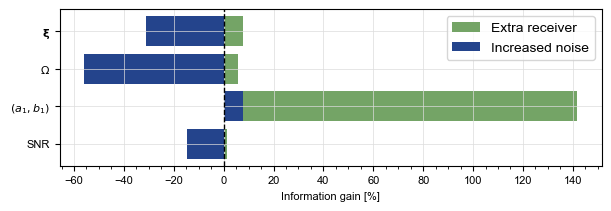

In [7]:
#__ Create figure and axes __
fig, ax = plt.subplots(figsize=(6,2), facecolor='white', layout='constrained')

#__ Format __
ax.set_xlabel("Information gain [%]", fontsize=small)
ax.xaxis.set_major_locator(ticker.MultipleLocator(20))
ax.xaxis.set_minor_locator(ticker.MultipleLocator(5))
ax.tick_params(labelsize=small)
ax.grid(color='gainsboro', linewidth=0.5)

#__ Labels __
y      = np.arange(4)[::-1]
labels = [r"$\mathbf{\xi}$", r"$\Omega$", r"$\left(a_1, b_1\right)$", r"SNR"]
ax.set_yticks(y, labels)

#__ Plot information gain __
ax.barh(y, rel_IG_quad, color=theme[1], label="Extra receiver", zorder=1)
ax.barh(y, rel_IG_noisy, color=theme[2], label="Increased noise", zorder=1)

#__ Plot neutral __
ax.axvline(0, c='k', ls='--', lw=1.0, zorder=2)

#__ Legend __
ax.legend(fontsize=large)

#__ Show figure __
fig.show()